## Section 0 - Setup

In [1]:
import warnings, pickle, ast, os, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
NAVY, TEAL, GREY, RED, AMBER = "#0B2545", "#13A89E", "#8D99AE", "#D62839", "#F4A261"

ROOT = Path("..")
MODEL_CSV  = ROOT/"data_processed"/"metro_trips_model_ready.csv"
SARIMA_CSV = ROOT/"docs"/"sarima_results_final.csv"
LSTM_CSV   = ROOT/"docs"/"lstm_results_summary.csv"
OUT = ROOT/"docs"/"Evidence"/"ch8"; FIG, TAB = OUT/"figures", OUT/"tables"
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)
HOLDOUT, WINDOW = 6, 12

def save_fig(fig, label, slug):
    p = FIG/f"{label.replace(' ', '_')}_{slug}.png"; fig.savefig(p, bbox_inches="tight", facecolor="white"); print("saved", p); plt.show()
def save_table(df, label, slug):
    stem = TAB/f"{label.replace(' ', '_')}_{slug}"
    df.to_csv(str(stem) + ".csv", index=False); df.to_html(str(stem) + ".html", index=False); print("saved", stem.name); return df
def mape(a, f): a, f = np.asarray(a, float), np.asarray(f, float); return float(np.mean(np.abs((a - f) / a)) * 100)

model = pd.read_csv(MODEL_CSV, parse_dates=["date"]).sort_values(["metro_station", "date"])
sar, lst = pd.read_csv(SARIMA_CSV), pd.read_csv(LSTM_CSV)
comp = sar[["station","order","seasonal_order","MAPE_sarima","RMSE_sarima","MAE_sarima"]].merge(lst[["station","MAPE_lstm","RMSE_lstm","MAE_lstm"]], on="station", how="outer")
both = comp.dropna(subset=["MAPE_lstm"])
def full_name(short):
    hits = [s for s in model.metro_station.unique() if short.lower() in s.lower()]
    assert len(hits) == 1, f"'{short}' matched {hits}"; return hits[0]
def get_series(name):
    s = model[model.metro_station == full_name(name)].set_index("date")["trips"].asfreq("MS")
    return s.interpolate("linear").bfill().ffill()
assert len(model) == 3405 and comp.station.nunique() == 53, "unexpected data - check file paths"
print("loaded OK:", len(model), "model rows;", len(comp), "stations;", len(both), "with both models")

loaded OK: 3405 model rows; 53 stations; 51 with both models


## Section A - Check every number in the Chapter 8 text
Each line shows the number used in the text, the number in your data, and `OK` or `CHECK`. For `CHECK`, either your data differ from my wording or a rounded number needs adjusting. Change the text number (same word count) and tell me if anything material differs.

In [2]:
from scipy.stats import wilcoxon, rankdata, binomtest
rows = []
def check(label, text, data, tol=0.0):
    ok = abs(float(text) - float(data)) <= tol if isinstance(text, (int, float)) and isinstance(data, (int, float, np.floating)) else (text == data)
    rows.append((label, text, round(float(data), 3) if isinstance(data, (int, float, np.floating)) else data, "OK" if ok else "CHECK"))

# ---- accuracy (8.3.1) ----
q = comp[["MAPE_sarima", "MAPE_lstm"]].quantile([.25, .5, .75])
check("SARIMA median MAPE", 7.27, comp.MAPE_sarima.median(), .01); check("LSTM median MAPE", 12.37, comp.MAPE_lstm.median(), .01)
check("LSTM mean MAPE", 24.39, comp.MAPE_lstm.mean(), .01)
check("SARIMA Q1", 6.45, q.loc[.25, "MAPE_sarima"], .01); check("SARIMA Q3", 8.52, q.loc[.75, "MAPE_sarima"], .01)
check("LSTM Q1", 9.76, q.loc[.25, "MAPE_lstm"], .01);   check("LSTM Q3", 18.01, q.loc[.75, "MAPE_lstm"], .01)
check("stations with SARIMA MAPE < 10%", 45, int((comp.MAPE_sarima < 10).sum()))
check("SARIMA mean RMSE", 45261, comp.RMSE_sarima.mean(), 1); check("LSTM mean RMSE", 81632, comp.RMSE_lstm.mean(), 1)
check("SARIMA mean MAE", 37692, comp.MAE_sarima.mean(), 1);   check("LSTM mean MAE", 71748, comp.MAE_lstm.mean(), 1)
best, worst = comp.loc[comp.MAPE_sarima.idxmin()], comp.loc[comp.MAPE_sarima.idxmax()]
check("SARIMA best station", "Gold Souq", best.station.replace(" Metro Station", "")); check("SARIMA best MAPE", 4.5, best.MAPE_sarima, .05)
check("SARIMA worst station", "EXPO", worst.station.replace(" Metro Station", "")); check("SARIMA worst MAPE", 29.7, worst.MAPE_sarima, .05)
# ---- head to head (8.3.2 / 8.3.3) ----
d = both.assign(diff=both.MAPE_lstm - both.MAPE_sarima)
check("SARIMA wins (51 stations)", 47, int((d["diff"] > 0).sum())); check("LSTM wins", 4, int((d["diff"] < 0).sum()))
wins = d[d["diff"] < 0]; print("LSTM wins:", [(r.station.replace(' Metro Station',''), round(r.MAPE_sarima,1), round(r.MAPE_lstm,1)) for r in wins.itertuples()])
check("every LSTM win margin < 2 points", True, bool((wins["diff"].abs() < 2).all()))
check("LSTM wins with SARIMA error 7.3-9.6% (text: three)", 3, int(((wins.MAPE_sarima >= 7.25) & (wins.MAPE_sarima <= 9.65)).sum()))
close = d[(d["diff"] > 0) & (d["diff"] <= 1.05)]; print("LSTM lost by <= ~1 point:", [(r.station.replace(' Metro Station',''), round(r.diff,2)) for r in close.itertuples()])
check("stations where LSTM lost by about one point or less (text: five)", 5, len(close))
r_ = rankdata(np.abs(d["diff"])); Wp, Wm = r_[d["diff"] > 0].sum(), r_[d["diff"] < 0].sum()
w = wilcoxon(both.MAPE_sarima, both.MAPE_lstm)
check("Wilcoxon p < 0.001 (1 = true)", 1, int(w.pvalue < .001)); check("rank-biserial r", 0.95, (Wp - Wm) / (Wp + Wm), .01)
# ---- case studies (8.4) ----
srank = comp.assign(r=comp.MAPE_sarima.rank(method="min")); check("BurJuman SARIMA rank (best=1)", 3, int(srank[srank.station.str.contains("BurJuman")].r.iloc[0]))
check("World Trade Centre rank from worst", 8, int(comp.MAPE_sarima.rank(ascending=False, method="min")[comp.station.str.contains("World Trade")].iloc[0]))
for nm, s_, l_ in [("BurJuman", 4.8, 9.7), ("World Trade Centre", 10.7, 21.3), ("EXPO", 29.7, 435.1), ("Jumeirah Golf Estates", 10.9, 61.2), ("Energy", 14.2, 90.4)]:
    rr = comp[comp.station.str.contains(nm)].iloc[0]; check(f"{nm} SARIMA MAPE", s_, rr.MAPE_sarima, .05); check(f"{nm} LSTM MAPE", l_, rr.MAPE_lstm, .05)
# ---- EDA (8.2) ----
sysm = model.groupby("date").trips.sum().asfreq("MS")
y1819 = sysm["2018":"2019"]; y23 = sysm["2023-01":"2023-08"]
print(f"\nSystem-wide monthly trips: 2018-19 range {y1819.min()/1e6:.1f}-{y1819.max()/1e6:.1f}M (text: roughly 15-18M); 2023 Jan-Aug range {y23.min()/1e6:.1f}-{y23.max()/1e6:.1f}M (text: roughly 24-29M)")
print(f"Peak month {sysm.idxmax():%b %Y} ({sysm.max()/1e6:.1f}M) (text: March 2022 spike); lowest month {sysm.idxmin():%b %Y} ({sysm.min()/1e6:.2f}M)")
check("2018-19 minimum within 14.5-15.5M", 1, int(14.5e6 <= y1819.min() <= 15.5e6)); check("2018-19 maximum within 17.5-18.8M", 1, int(17.5e6 <= y1819.max() <= 18.8e6))
check("2023 minimum within 23.5-25.5M", 1, int(23.5e6 <= y23.min() <= 25.5e6)); check("2023 maximum within 28.5-29.8M", 1, int(28.5e6 <= y23.max() <= 29.8e6))
check("peak month is March 2022", "2022-03", f"{sysm.idxmax():%Y-%m}")
x = model[((model.date < "2020-03-01") | (model.date >= "2022-01-01")) & ~model.metro_station.str.contains("EXPO")].copy()
x = x[x.groupby("metro_station").trips.transform("size") >= 12]; x["norm"] = x.trips / x.groupby("metro_station").trips.transform("mean"); x["m"] = x.date.dt.month
med, mean_ = x.groupby("m").norm.median(), x.groupby("m").norm.mean()
check("seasonal swing (percent of station mean)", 21, (mean_.max() - mean_.min()) * 100, 1.0)
check("peak month (3 = March)", 3, int(mean_.idxmax())); check("trough month (9 = September)", 9, int(mean_.idxmin()))
check("median index March", 1.13, med[3], .01); check("median index September", 0.87, med[9], .01)
check("June-September medians all below 1 (1 = true)", 1, int((med[[6, 7, 8, 9]] < 1).all()))
out = pd.DataFrame(rows, columns=["Claim in text", "Text value", "Your data", "Result"])
print(out.to_string(index=False)); print("\nCHECK lines:", int((out.Result == "CHECK").sum()), "of", len(out))
save_table(out, "Table A.8", "number_check")

LSTM wins: [('Abu Baker Al Siddique', 7.3, 6.4), ('Dubai Investment Park', 13.4, 12.4), ('Etisalat', 7.9, 6.1), ('Ibn Battuta', 9.6, 7.8)]
LSTM lost by <= ~1 point: [('Abu Hail', 0.99), ('Baniyas Square', 0.57), ('Danube', 0.26), ('Jabal Ali', 0.94), ('Union', 0.66)]

System-wide monthly trips: 2018-19 range 15.0-18.3M (text: roughly 15-18M); 2023 Jan-Aug range 24.3-29.2M (text: roughly 24-29M)
Peak month Mar 2022 (29.5M) (text: March 2022 spike); lowest month Nov 2020 (0.50M)
                                                   Claim in text Text value  Your data Result
                                              SARIMA median MAPE       7.27      7.274     OK
                                                LSTM median MAPE      12.37     12.371     OK
                                                  LSTM mean MAPE      24.39     24.394     OK
                                                       SARIMA Q1       6.45      6.528  CHECK
                                                

,Claim in text,Text value,Your data,Result
0,SARIMA median MAPE,7.27,7.274,OK
1,LSTM median MAPE,12.37,12.371,OK
2,LSTM mean MAPE,24.39,24.394,OK
3,SARIMA Q1,6.45,6.528,CHECK
4,SARIMA Q3,8.52,8.489,CHECK
5,LSTM Q1,9.76,9.836,CHECK
6,LSTM Q3,18.01,17.909,CHECK
7,stations with SARIMA MAPE < 10%,45,45.0,OK
8,SARIMA mean RMSE,45261,45261.153,OK
9,LSTM mean RMSE,81632,81631.609,OK


## Section B - Table 8.1 and Figures 8.1 to 8.6

In [3]:
# TABLE 8.1 - holdout accuracy by SARIMA error band
bands = [("Below 6%", 0, 6), ("6% to under 8%", 6, 8), ("8% to under 10%", 8, 10), ("10% and above", 10, 1e9)]
rows = []
for name, lo, hi in bands:
    g = comp[(comp.MAPE_sarima >= lo) & (comp.MAPE_sarima < hi)]; gl = g.dropna(subset=["MAPE_lstm"])
    rows.append([name, len(g), round(g.MAPE_sarima.median(), 2), round(gl.MAPE_lstm.median(), 2), int((gl.MAPE_lstm < gl.MAPE_sarima).sum())])
rows.append(["All stations", len(comp), round(comp.MAPE_sarima.median(), 2), round(comp.MAPE_lstm.median(), 2), int((both.MAPE_lstm < both.MAPE_sarima).sum())])
t81 = pd.DataFrame(rows, columns=["SARIMA error band", "Stations", "SARIMA median MAPE (%)", "LSTM median MAPE (%)", "LSTM wins"])
save_table(t81, "Table 8.1", "accuracy_by_error_band"); print("LSTM median higher in every band (text claim):", bool((t81["LSTM median MAPE (%)"] > t81["SARIMA median MAPE (%)"]).all())); t81

saved Table_8.1_accuracy_by_error_band
LSTM median higher in every band (text claim): True


,SARIMA error band,Stations,SARIMA median MAPE (%),LSTM median MAPE (%),LSTM wins
0,Below 6%,9,5.19,9.98,0
1,6% to under 8%,26,7.13,11.59,2
2,8% to under 10%,10,8.55,14.84,1
3,10% and above,8,13.27,29.80,1
4,All stations,53,7.27,12.37,4


### Figure 8.1 - System-wide monthly trips, validated window


saved ..\docs\Evidence\ch8\figures\Figure_8.1_system_trend_validated.png


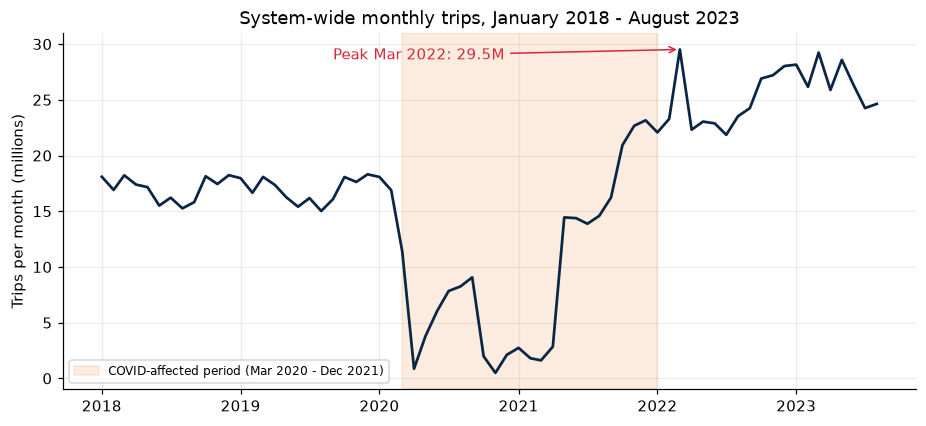

In [4]:
sysm = model.groupby("date").trips.sum().asfreq("MS") / 1e6
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(sysm.index, sysm.values, c=NAVY, lw=1.8)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color=AMBER, alpha=.2, label="COVID-affected period (Mar 2020 - Dec 2021)")
pk = sysm.idxmax(); ax.annotate(f"Peak {pk:%b %Y}: {sysm.max():.1f}M", xy=(pk, sysm.max()), xytext=(pd.Timestamp("2019-09-01"), sysm.max() * .97), arrowprops=dict(arrowstyle="->", color=RED), color=RED)
ax.set(ylabel="Trips per month (millions)", title="System-wide monthly trips, January 2018 - August 2023"); ax.legend(loc="lower left", fontsize=8)
save_fig(fig, "Figure 8.1", "system_trend_validated")

### Figure 8.2 - Seasonal pattern summary


saved ..\docs\Evidence\ch8\figures\Figure_8.2_seasonal_summary.png


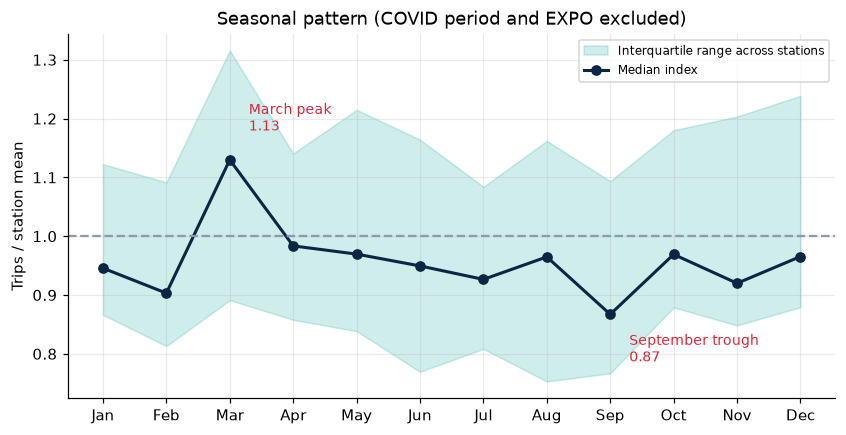

In [5]:
x = model[((model.date < "2020-03-01") | (model.date >= "2022-01-01")) & ~model.metro_station.str.contains("EXPO")].copy()
x = x[x.groupby("metro_station").trips.transform("size") >= 12]; x["norm"] = x.trips / x.groupby("metro_station").trips.transform("mean"); x["m"] = x.date.dt.month
g = x.groupby("m").norm; med, q1, q3 = g.median(), g.quantile(.25), g.quantile(.75)
fig, ax = plt.subplots(figsize=(9, 4.3)); mn = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ax.fill_between(range(1, 13), q1, q3, color=TEAL, alpha=.2, label="Interquartile range across stations")
ax.plot(range(1, 13), med, c=NAVY, marker="o", lw=2, label="Median index"); ax.axhline(1, c=GREY, ls="--")
for m_, lab in [(3, "March peak"), (9, "September trough")]: ax.annotate(f"{lab}\n{med[m_]:.2f}", xy=(m_, med[m_]), xytext=(m_ + .3, med[m_] + (.05 if m_ == 3 else -.08)), color=RED, fontsize=9)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(mn); ax.set(ylabel="Trips / station mean", title="Seasonal pattern (COVID period and EXPO excluded)"); ax.legend(fontsize=8)
save_fig(fig, "Figure 8.2", "seasonal_summary")

### Figure 8.3 - MAPE distribution, SARIMA vs LSTM


saved ..\docs\Evidence\ch8\figures\Figure_8.3_mape_distribution.png


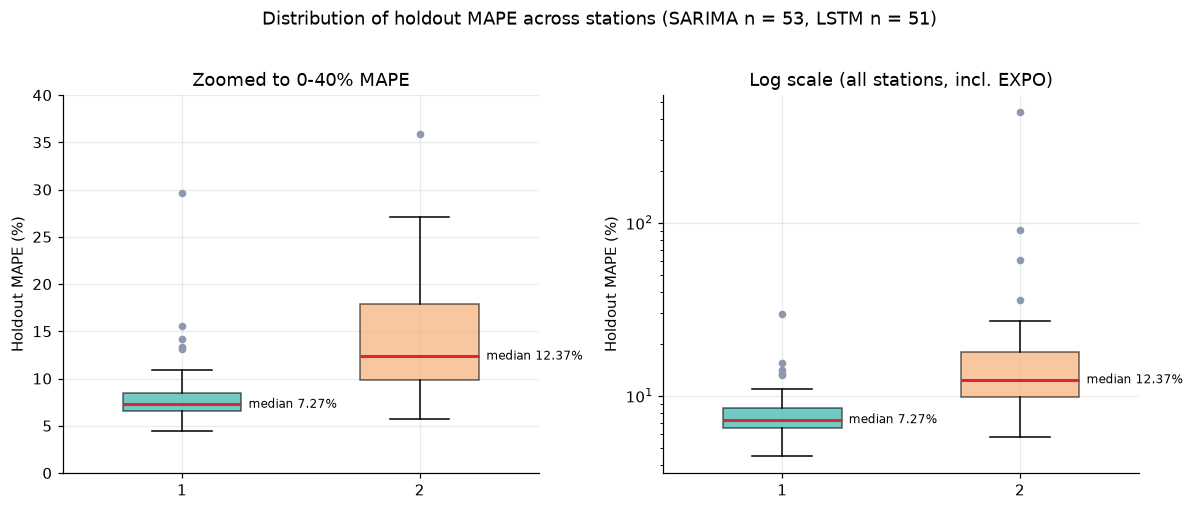

In [6]:
data = [comp.MAPE_sarima.dropna().values, comp.MAPE_lstm.dropna().values]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, log in zip(axes, [False, True]):
    bp = ax.boxplot(data, label=["SARIMA", "LSTM"], patch_artist=True, widths=.5, flierprops=dict(marker="o", ms=4, mfc=GREY, mec=GREY), medianprops=dict(color=RED, lw=2))
    for patch, col in zip(bp["boxes"], [TEAL, AMBER]): patch.set_facecolor(col); patch.set_alpha(.6)
    for i, d_ in enumerate(data, 1): ax.text(i + .28, np.median(d_), f"median {np.median(d_):.2f}%", va="center", fontsize=8)
    if log: ax.set_yscale("log"); ax.set_title("Log scale (all stations, incl. EXPO)")
    else: ax.set_ylim(0, 40); ax.set_title("Zoomed to 0-40% MAPE")
    ax.set_ylabel("Holdout MAPE (%)")
fig.suptitle("Distribution of holdout MAPE across stations (SARIMA n = 53, LSTM n = 51)", y=1.02); fig.tight_layout()
save_fig(fig, "Figure 8.3", "mape_distribution")

### Figures 8.4, 8.5, 8.6 - Case-study forecasts (BurJuman, World Trade Centre, EXPO)


saved ..\docs\Evidence\ch8\figures\Figure_8.4_case_burjuman.png


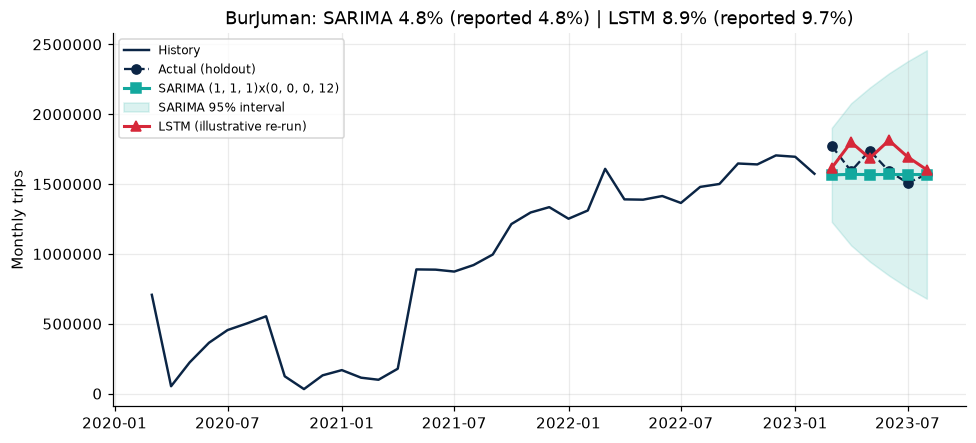

(4.755642665747365, 8.87679724114262)

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX

def make_sequences(data, window=WINDOW):
    X, y = [], []
    for i in range(len(data) - window): X.append(data[i:i+window]); y.append(data[i+window])
    return np.array(X), np.array(y)
def new_model():
    m = Sequential([LSTM(50, activation="relu", input_shape=(WINDOW, 1)), Dense(1)]); m.compile(optimizer="adam", loss="mse"); return m
def lstm_asrun(series, n_runs=3, epochs=200):
    sc = MinMaxScaler(); z = sc.fit_transform(series.values.reshape(-1, 1))            # as run: full-series scaler
    X, y = make_sequences(z); Xtr, ytr, Xte = X[:-HOLDOUT], y[:-HOLDOUT], X[-HOLDOUT:]; runs = []
    for _ in range(n_runs):
        m = new_model(); m.fit(Xtr, ytr, epochs=epochs, batch_size=8, verbose=0, callbacks=[EarlyStopping(monitor="loss", patience=15, restore_best_weights=True)])
        runs.append(sc.inverse_transform(m.predict(Xte, verbose=0)).flatten())
    return np.mean(runs, axis=0)

def case_figure(short, label, slug, history=36):
    fn = full_name(short); s = get_series(short); row = comp[comp.station == fn].iloc[0]
    order, seas = ast.literal_eval(row.order), ast.literal_eval(row.seasonal_order)
    tr, te = s.iloc[:-HOLDOUT], s.iloc[-HOLDOUT:]
    fit = SARIMAX(tr, order=order, seasonal_order=seas, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = fit.get_forecast(HOLDOUT); pm, ci = fc.predicted_mean, fc.conf_int(); lp = pd.Series(lstm_asrun(s), index=te.index)
    ms, ml = mape(te, pm), mape(te, lp)
    fig, ax = plt.subplots(figsize=(10, 4.4)); h = tr if history is None else tr.iloc[-history:]
    ax.plot(h.index, h.values, c=NAVY, lw=1.6, label="History"); ax.plot(te.index, te.values, c=NAVY, ls="--", marker="o", label="Actual (holdout)")
    ax.plot(pm.index, pm.values, c=TEAL, marker="s", lw=2, label=f"SARIMA {order}x{seas}"); ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=TEAL, alpha=.15, label="SARIMA 95% interval")
    ax.plot(lp.index, lp.values, c=RED, marker="^", lw=2, label="LSTM (illustrative re-run)")
    ax.set(ylabel="Monthly trips", title=f"{short}: SARIMA {ms:.1f}% (reported {row.MAPE_sarima:.1f}%) | LSTM {ml:.1f}% (reported {row.MAPE_lstm:.1f}%)"); ax.ticklabel_format(axis="y", style="plain"); ax.legend(fontsize=8)
    save_fig(fig, label, slug); return ms, ml

case_figure("BurJuman", "Figure 8.4", "case_burjuman")

saved ..\docs\Evidence\ch8\figures\Figure_8.5_case_world_trade_centre.png


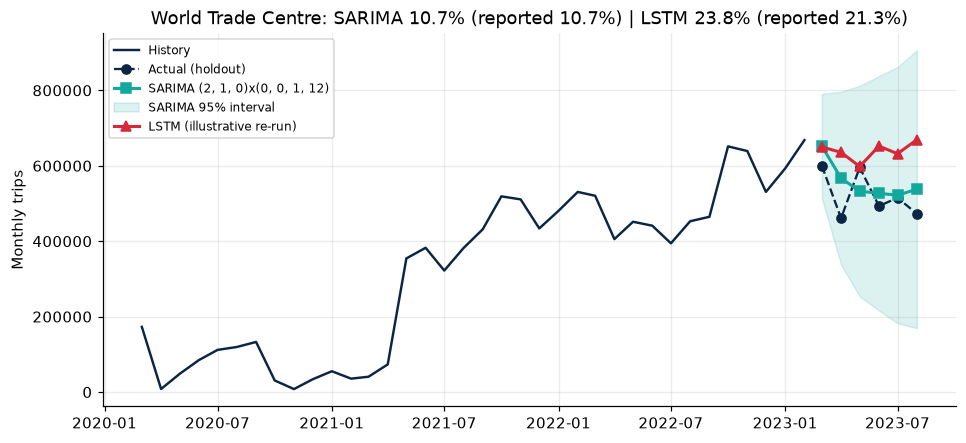

(10.691961129411082, 23.830479737113297)

In [8]:
case_figure("World Trade Centre", "Figure 8.5", "case_world_trade_centre")

c:\Users\user\Desktop\RES6011_Computing-Project\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


saved ..\docs\Evidence\ch8\figures\Figure_8.6_case_expo_structural_break.png


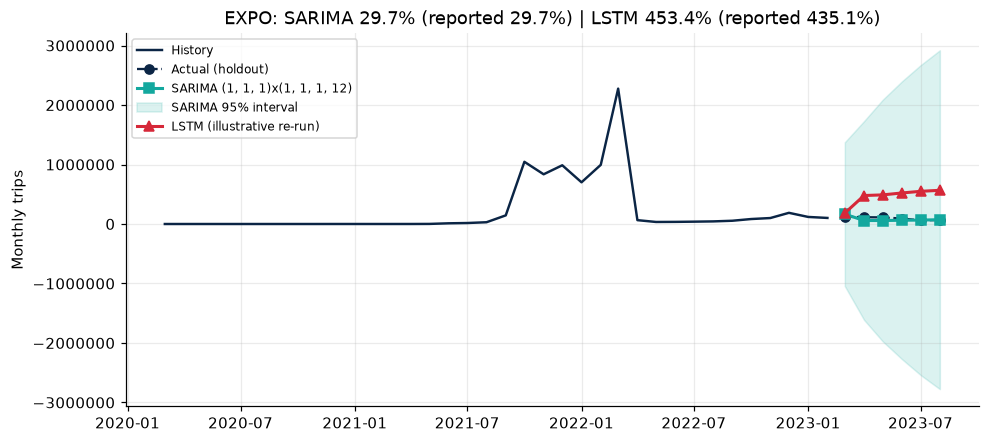

(29.652365020695775, 453.3983314772207)

In [9]:
# EXPO: show the whole series (history=None) so the structural break is visible; the LSTM over-forecast will be very large
case_figure("EXPO", "Figure 8.6", "case_expo_structural_break", history=None)